# 03d — Eventos espaciotemporales

¿Cuántos incendios reales hay detrás de las detecciones, y atraviesa un mismo incendio varios regímenes de condiciones? Un incendio se detecta varios días seguidos: DBSCAN sobre (x_km, y_km, día) agrupa esas redetecciones en eventos. Entrada: `lags_index.csv` (columnas del conjunto D) + `features_a.csv` (PCs para la meteo media) + etiquetas de 03b y banderas de 03c para el cruce. Salida: `unsupervised/eventos.csv` + `unsupervised/eventos_resumen.csv`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wildfire.data.io import load_csv, save_csv
from wildfire.processing.events import (
    DAY_KM_SENSITIVITY, DEFAULT_DAY_KM, DEFAULT_MIN_SAMPLES, EVENT_MATRIX_COLS,
    NOISE_LABEL, anomaly_density_per_event, build_event_matrix,
    cluster_span_per_event, fit_dbscan_events, k_distance_curve, summarize_events,
)
from wildfire.processing.unsupervised import ENTRADA_D


## 03d.1 — Matriz de eventos

Se cargan las columnas del conjunto D (`latitude`, `longitude`, `acq_date`) y se construye el espacio DBSCAN: coordenadas a km (EPSG:3035, que sí cubre Canarias) y día como índice entero desde la primera detección, estirado para que 1 día cuente como 7,5 km (así se puentean los huecos entre pasadas del satélite). El índice se conserva para reenganchar las etiquetas por posición.


In [2]:
base = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")
print(f"base: {base.shape} | columnas D presentes: {[c for c in ENTRADA_D if c in base.columns]}")
matriz = build_event_matrix(base)
print(f"matriz: {matriz.shape} (columnas: {list(matriz.columns)})")
display(matriz.describe().T)


base: (23142, 61) | columnas D presentes: ['latitude', 'longitude', 'acq_date']
matriz: (23142, 4) (columnas: ['x_km', 'y_km', 'day', 'day_scaled'])


,count,mean,std,min,25%,50%,75%,max
x_km,23142.0,2939.645756,489.386405,1561.399448,2920.842800,3004.406410,3193.957116,3821.178170
y_km,23142.0,1956.002599,406.522463,945.229197,1754.341622,2033.080505,2326.391002,2456.746221
day,23142.0,300.142123,209.720611,0.000000,96.000000,229.000000,523.000000,730.000000
day_scaled,23142.0,2251.065919,1572.904581,0.000000,720.000000,1717.500000,3922.500000,5475.000000


## 03d.2 — Curva k-distancia y elección de eps

Cómo leer la figura: curva de distancias al tercer vecino ordenadas; la rodilla separa el núcleo denso (redetecciones del mismo píxel, distancias bajo el km) de la cola (incendios distintos, decenas de km). La tabla barre candidatos a eps para que la elección sea auditable: se busca una zona donde el número de eventos y la fracción de ruido se estabilicen.


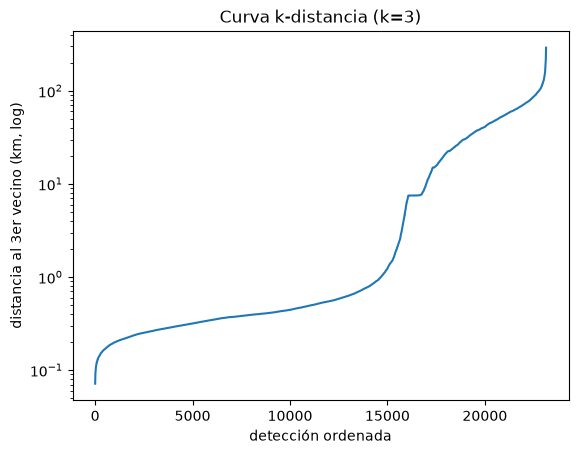

,eps,eventos,ruido,mediana_n,max_n
0,5.0,1439,0.255,5,1209
1,10.0,1177,0.214,5,2100
2,15.0,1139,0.199,5,2714
3,20.0,1124,0.172,5,2791


EPS = 10.0


In [3]:
curva = k_distance_curve(matriz[["x_km", "y_km", "day_scaled"]], k=DEFAULT_MIN_SAMPLES)
fig, ax = plt.subplots()
ax.plot(curva)
ax.set_yscale("log")
ax.set_xlabel("detección ordenada")
ax.set_ylabel("distancia al 3er vecino (km, log)")
ax.set_title("Curva k-distancia (k=3)")
plt.show()

X = matriz[["x_km", "y_km", "day_scaled"]].to_numpy()
barrido = []
for eps in [5.0, 10.0, 15.0, 20.0]:
    lab = fit_dbscan_events(X, eps=eps)
    sizes = pd.Series(lab[lab != NOISE_LABEL]).value_counts()
    barrido.append({"eps": eps, "eventos": len(sizes), "ruido": round(float((lab == NOISE_LABEL).mean()), 3),
                        "mediana_n": int(sizes.median()), "max_n": int(sizes.max())})
display(pd.DataFrame(barrido))

# Elegido en la rodilla aproximada (zona 5-15 km) y en el tramo estable del barrido.
EPS = 10.0
print(f"EPS = {EPS}")


## 03d.3 — DBSCAN y sensibilidad a la escala día-km

El único parámetro con física detrás es cuántos km vale un día (un incendio avanza km al día, no decenas). Se repite el ajuste en {5, 7,5, 10} km/día con el mismo eps: si el conteo de eventos cambiara radicalmente, la tipología de eventos dependería del parámetro y no de los datos. Se guarda `eventos.csv` (una fila por detección, en el mismo orden que la base).


In [4]:
sensib = []
etiquetas = {}
for day_km in DAY_KM_SENSITIVITY:
    m = build_event_matrix(base, day_km=day_km)
    lab = fit_dbscan_events(m[["x_km", "y_km", "day_scaled"]], eps=EPS)
    etiquetas[day_km] = lab
    sizes = pd.Series(lab[lab != NOISE_LABEL]).value_counts()
    sensib.append({"km_por_dia": day_km, "eventos": len(sizes),
                   "ruido": round(float((lab == NOISE_LABEL).mean()), 3),
                   "mediana_n": int(sizes.median()), "max_n": int(sizes.max())})
display(pd.DataFrame(sensib))

event_id = pd.Series(etiquetas[DEFAULT_DAY_KM], index=base.index, name="event_id")
assert len(event_id) == len(base)
save_csv(event_id.to_frame(), "data/processed/unsupervised/eventos.csv")
print(f"eventos: {event_id.nunique() - (1 if (event_id == NOISE_LABEL).any() else 0)} | ruido: {(event_id == NOISE_LABEL).mean():.3f}")


,km_por_dia,eventos,ruido,mediana_n,max_n
0,5.0,1172,0.211,5,2100
1,7.5,1177,0.214,5,2100
2,10.0,1382,0.242,5,1209


eventos: 1177 | ruido: 0.214


## 03d.4 — Resumen por evento

Tabla a nivel de incendio (no de detección): tamaño, duración, centroide, mezcla de CCAA, FRP máximo y meteorología media (PCs del conjunto A). El ruido (-1) no es un fracaso: son detecciones aisladas (p. ej. quemas puntuales) y se perfila aparte por CLC y CCAA.


In [5]:
feat_a = load_csv("data/processed/unsupervised/features_a.csv")
assert len(feat_a) == len(base) == len(matriz)
cuadro = pd.DataFrame({"x_km": matriz["x_km"], "y_km": matriz["y_km"], "day": matriz["day"],
                       "ccaa": base["ccaa"].to_numpy(), "frp": base["frp"].to_numpy()})
for c in feat_a.columns:
    cuadro[c] = feat_a[c].to_numpy()
resumen = summarize_events(cuadro, event_id.to_numpy(), pc_cols=list(feat_a.columns))
save_csv(resumen, "data/processed/unsupervised/eventos_resumen.csv")
print(f"resumen: {resumen.shape}")
display(resumen[["n", "duration_days", "ccaa_n", "frp_max"]].describe().T)

ruido_mask = event_id.to_numpy() == NOISE_LABEL
print(f"fracción de ruido: {ruido_mask.mean():.3f}")
print("CLC del ruido (top):")
print(base.loc[ruido_mask, "clc_class"].value_counts().head(5).to_string())
print("CCAA del ruido (top):")
print(base.loc[ruido_mask, "ccaa"].value_counts().head(5).to_string())


resumen: (1177, 19)


,count,mean,std,min,25%,50%,75%,max
n,1177.0,15.462192,92.223187,3.00,3.0,5.00,8.0,2100.0
duration_days,1177.0,1.519116,2.331721,1.00,1.0,1.00,2.0,74.0
ccaa_n,1177.0,1.019541,0.138476,1.00,1.0,1.00,1.0,2.0
frp_max,1177.0,44.739660,121.026189,0.31,4.6,10.88,30.6,1369.5


fracción de ruido: 0.214
CLC del ruido (top):
clc_class
5    950
7    874
4    741
6    737
9    708
CCAA del ruido (top):
ccaa
Andalucía               1125
Castilla-La Mancha       582
Extremadura              525
Castilla y León          387
Comunidad Valenciana     379


## 03d.5 — Cruce con 03b (regímenes) y 03c (anomalías)

La pregunta interesante: ¿atraviesa un evento varios regímenes de condiciones (etiquetas 03b al k ilustrativo 5 del conjunto A; 03e lo repetirá al k elegido), y concentran anomalías los eventos largos o van por libre (bandera de consenso del conjunto A)?


In [6]:
cl = load_csv("data/processed/unsupervised/cluster_labels.csv")
an = load_csv("data/processed/unsupervised/anomalias_a.csv")
assert len(cl) == len(an) == len(base)
span = cluster_span_per_event(event_id[event_id != NOISE_LABEL], cl.loc[event_id != NOISE_LABEL, "kmeans_a_k5"])
print("Regímenes distintos por evento:")
print(span["n_clusters"].value_counts().sort_index().to_string())
print(f"eventos multirrégimen: {(span['n_clusters'] > 1).mean():.3f}")

dens = anomaly_density_per_event(event_id, an["consenso_flag"].to_numpy())
dens_ev = dens[dens["event_id"] != NOISE_LABEL].merge(resumen[["event_id", "duration_days"]], on="event_id")
print(f"densidad media de anomalías en eventos: {dens_ev['frac_flagged'].mean():.4f}")
print("Anomalías por duración del evento:")
print(dens_ev.groupby(pd.cut(dens_ev["duration_days"], [0, 1, 3, 7, 400]))["frac_flagged"].mean().to_string())


Regímenes distintos por evento:
n_clusters
1    836
2    272
3     60
4      8
5      1
eventos multirrégimen: 0.290


densidad media de anomalías en eventos: 0.0051
Anomalías por duración del evento:
duration_days
(0, 1]      0.004182
(1, 3]      0.007891
(3, 7]      0.000965
(7, 400]    0.010079


## 03d.6 — Mapa de eventos

Cómo leerlo: cada punto es un evento (centroide); el tamaño crece con el número de detecciones y el color con la duración. Sirve para ver si los eventos grandes y largos se concentran en alguna zona o se reparten.


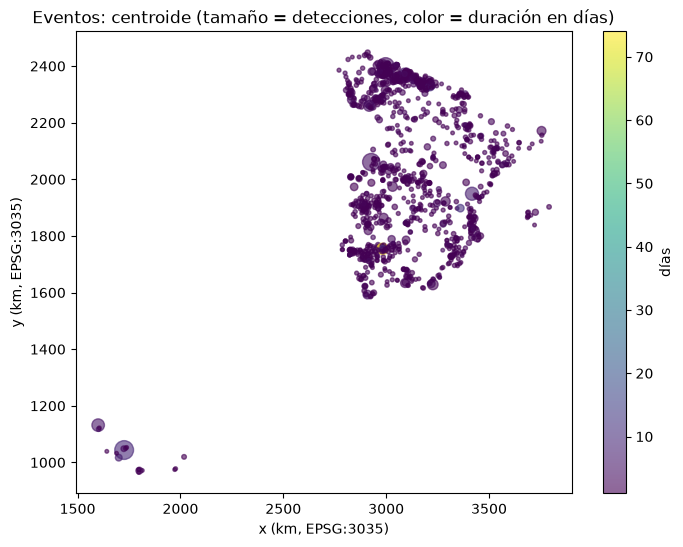

eventos dibujados: 1177


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(resumen["x_centroid_km"], resumen["y_centroid_km"],
                s=np.sqrt(resumen["n"]) * 4, c=resumen["duration_days"],
                cmap="viridis", alpha=0.6)
ax.set_xlabel("x (km, EPSG:3035)")
ax.set_ylabel("y (km, EPSG:3035)")
ax.set_title("Eventos: centroide (tamaño = detecciones, color = duración en días)")
plt.colorbar(sc, ax=ax, label="días")
plt.show()
print(f"eventos dibujados: {len(resumen)}")


## Cierre 03d

Quedan `eventos.csv` (etiqueta por detección, -1 = ruido) y `eventos_resumen.csv` (tabla por incendio) para 03e: la estabilidad temporal (¿replican los eventos 2023 en 2024?) y la utilidad (¿separan severidad?) entran en la validación final.
